In [67]:
# Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold


In [68]:
df = pd.read_csv("data/structured_routing.csv")
dd = pd.read_csv("data/data_dictionary.csv")

# Take the column roles from the dictionary
FEATURES = dd.loc[dd.role == "pre_routing_feature", "column"].tolist()
TARGETS = dd.loc[dd.role == "target", "column"].tolist()
EVAL_ONLY = dd.loc[dd.role == "evaluation_only", "column"].tolist()
IDS = dd.loc[dd.role == "identifier", "column"].tolist()

print(len(FEATURES), len(TARGETS), len(EVAL_ONLY), len(IDS))
assert len(FEATURES) == 19 # Make sure the number of features is correct
assert set(FEATURES).isdisjoint(TARGETS + EVAL_ONLY + IDS) # Make sure the features are disjoint from the other roles

TARGET = "brier_improvement" # Primary target, as per the instructions (if we decide to include a cost prediction model as well, there will be a separate target for that)

19 3 23 4


In [69]:
train = df[df.split == "train"].copy()
val = df[df.split == "validation"].copy()
test = df[df.split == "test"].copy()

print(len(train), len(val), len(test))
print(train.question_id.nunique(), val.question_id.nunique(), test.question_id.nunique())

# 1) No question appears in two splits
q_tr, q_va, q_te = map(lambda d: set(d.question_id), (train, val, test))
assert q_tr.isdisjoint(q_va) and q_tr.isdisjoint(q_te) and q_va.isdisjoint(q_te)

# 2) Every train date is earlier than every val date, which is earlier than every test date
assert train.date.max() < val.date.min() and val.date.max() < test.date.min()

# 3) The target and evaluation-only columns are ALL missing in the test rows.
assert test[TARGETS + EVAL_ONLY].isna().all().all()

# 4) The target columns are fully present (no NaN) in train and val, so we have labels for training and for validation scoring.
assert train[TARGETS].notna().all().all() and val[TARGETS].notna().all().all()

714 170 215
151 34 43


In [70]:
# Feature sets for ablations

UNCERTAINTY = ["direct_uncertainty"]

MARKET = [
    "external_market_probability",
    "external_market_uncertainty",
    "direct_market_disagreement",
]

USAGE = [
    "direct_prompt_tokens",
    "direct_completion_tokens",
    "direct_reasoning_tokens",
    "direct_tool_calls",
    "direct_llm_calls",
    "direct_agent_cost",
    "direct_filter_cost",
    "direct_total_cost",
]

FEATURE_SETS = {
    "all": FEATURES,
    "uncertainty": UNCERTAINTY,
    "market": MARKET,
    "usage": USAGE,
    "combined": UNCERTAINTY + MARKET + USAGE,
}

In [71]:
# Inputs and labels (Inputs are the same for both the benefit and the cost models, the targets differ)
CATEGORICAL_COLUMNS = ["source", "yhat_direct"]

# Only training data determines which categories get their own columns.
categories = {
    column: pd.CategoricalDtype(categories=sorted(train[column].unique()))
    for column in CATEGORICAL_COLUMNS
}

def make_features(split, columns):
    X = split[columns].copy()

    for column in X.select_dtypes(include="bool").columns:
        X[column] = X[column].astype(int)

    categorical = [column for column in CATEGORICAL_COLUMNS if column in X]
    for column in categorical:
        X[column] = X[column].astype(categories[column])

    return pd.get_dummies(X, columns=categorical, dtype=int)

X_train = {name: make_features(train, cols) for name, cols in FEATURE_SETS.items()}
X_val = {name: make_features(val, cols) for name, cols in FEATURE_SETS.items()}
X_test = {name: make_features(test, cols) for name, cols in FEATURE_SETS.items()}

y_train_benefit = train[TARGET].to_numpy()
y_val_benefit = val[TARGET].to_numpy()

y_train_cost = train["routed_agent_cost"].to_numpy()
y_val_cost = val["routed_agent_cost"].to_numpy()

for split in (train, val, test):
    assert split[FEATURES].notna().all().all()

assert train["routed_agent_cost"].notna().all()
assert val["routed_agent_cost"].notna().all()

# Keep all rows for a question in the same cross-validation fold
groups_train = train["question_id"].to_numpy()

### Implementation pipeline
1. Create four baseline models: 
    1. Always Direct (Always use the cheap, direct forecast--never route)
    2. Always Routed (Always use the expensive, routed forecast)
    3. Random Routing (Randomly choose between the direct and routed forecasts)
    4. Uncertainty Threshold (Route only when the direct forecast's uncertainty exceeds a chosen threshold $t$).

2. Evaluate these baseline models, based primarily on the **mean absolute brier score** they achieve across the data, as well as the **average agent cost** (all data contained in the data files we have been provided with). Due to a limited amount of data, we **use K-fold cross-validation on the training and the validation data together**, and average the results across the folds.

3. We can now select 2-3 simple models (like logistic regression for example, or even simple MLPs. Better to test the simple start first, and if we have time we can move onto the more complicated stuff which requires extra tuning) which we will train to be able to predict an accurate **brier improvement score**. The idea is as follows:
    1. Choose a model
    2. Train it using the training folds and the target which is the brier improvement score from our data, as well as all the different feature arangements we have created above. In the end, you should end up with 5 different models, all of which use the same learning algorithm but may produce different reults due to having seen different features.
    3. Once you have your models, you will use the same K folds (train and validation data together, like we did for the base models) in order to make your routinng decision on the held-out fold based on this routing rule: (the cost will be calculated ...)
    4. Once you have made your routing decisions, you will be able to yet again calculate the **mean absolute brier score** and the **average agent cost** (in the same manner as with the baselines), averaged across the folds, and you will be able to see how each of your models compares to eachother, as well as against the baselines.

4. From this point onward, some extra logging values need to be computed, but the hard part is essentially done (check the pdf for more details on these extra values!)

### Baselines

In [72]:
# Keep in mind that 0 = direct, 1 = routed. The routing functions should return a 1D array of 0s and 1s, with the same length as the input data.

# Always direct
def always_direct(data):
    return np.zeros(len(data), dtype=int)


# Always routed
def always_routed(data):
    return np.ones(len(data), dtype=int)


# Random routing
def random_routing(data, routing_rate=0.5, seed=42):
    rng = np.random.default_rng(seed)
    return rng.binomial(1, routing_rate, len(data))


# Uncertainty threshold
def uncertainty_threshold(data, t=0.5):
    return (data["direct_uncertainty"].to_numpy() > t).astype(int)

In [73]:
# Helper evaluation function for routing policies. This is used to evaluate the accuracy of a routing policy against the optimal routing decision, which is determined by comparing the true benefit and true cost of routing for each example.

def evaluate_router(router, data, lambdas, standalone=False, **router_kwargs):
    predictions = np.asarray(router(data, **router_kwargs))

    assert len(predictions) == len(data)
    assert np.isin(predictions, [0, 1]).all()

    # Actual Brier improvement
    true_benefit = data[TARGET].to_numpy()

    # Actual agent-side costs
    direct_cost = data["direct_agent_cost"].to_numpy()
    routed_cost = data["routed_agent_cost"].to_numpy()
    incremental_cost = routed_cost - direct_cost

    # 1. Routing accuracy for every lambda
    results = []

    for lam in lambdas:
        optimal = (true_benefit > lam * incremental_cost).astype(int)
        accuracy = np.mean(predictions == optimal)

        results.append({
            "lambda": lam,
            "accuracy": accuracy
        })

    # 2. Achieved Brier improvement
    # If we don't route, improvement is 0
    # If we route, improvement is the actual value
    achieved_improvement = predictions * true_benefit
    # 2b. Mean Brier of the forecast we actually use (direct if stop, routed if route)
    brier_used = np.where(predictions == 1, data["brier_routed"], data["brier_direct"])

    # 3. Actual cost of the selected workflow
    # A router always pays for the direct run, plus the routed run when it routes.
    # A standalone always-routed baseline only pays its own (routed) cost.
    if standalone:
        selected_cost = routed_cost
    else:
        selected_cost = direct_cost + predictions * routed_cost

    # 4. Forecast accuracy: is the forecast we ended up using correct? (yhat = -1 counts as wrong)
    yhat_used = np.where(predictions == 1, data["yhat_routed"], data["yhat_direct"])
    forecast_accuracy = np.mean(yhat_used == data["y"].to_numpy())

    return {
        "lambda_results": pd.DataFrame(results),
        "mean_accuracy": np.mean([r["accuracy"] for r in results]),
        "forecast_accuracy": forecast_accuracy,
        "mean_brier_improvement": np.mean(achieved_improvement),
        "mean_brier": np.mean(brier_used),
        "mean_cost": np.mean(selected_cost),
        "routing_rate": np.mean(predictions)
    }


In [74]:
# Development data = train + validation
dev = pd.concat([train, val], ignore_index=True)

# Grouped K-fold: all rows of a question stay in the same fold.
# Create the folds ONCE and reuse this exact `folds` list for every learned model later.
K = 5
folds = list(GroupKFold(n_splits=K).split(dev, groups=dev["question_id"]))

lambdas = np.round(np.arange(0.0, 1.01, 0.1), 2)
thresholds = np.round(np.arange(0.1, 1.0, 0.05), 2)


def average_folds(per_fold):
    # Average every metric across the held-out folds
    out = {k: np.mean([r[k] for r in per_fold]) for k in per_fold[0] if k != "lambda_results"}
    out["brier_std"] = np.std([r["mean_brier"] for r in per_fold], ddof=1)
    out["lambda_results"] = pd.DataFrame({
        "lambda": per_fold[0]["lambda_results"]["lambda"],
        "accuracy": np.mean([r["lambda_results"]["accuracy"].to_numpy() for r in per_fold], axis=0)
    })
    return out


def cv_evaluate(router, lambdas, standalone=False, **router_kwargs):
    # Evaluate on each held-out fold, then average
    return average_folds([
        evaluate_router(router, dev.iloc[test_idx], lambdas, standalone=standalone, **router_kwargs)
        for _, test_idx in folds
    ])


baselines = {
    "Always Direct": always_direct,
    "Always Routed": always_routed,
    "Random Routing": random_routing
}

all_results = {}

# First three baselines
for name, router in baselines.items():
    all_results[name] = cv_evaluate(router, lambdas, standalone=(name == "Always Routed"))

# All uncertainty thresholds (fixed t, averaged over the held-out folds)
for t in thresholds:
    name = f"Uncertainty (t={t:.2f}"  + ")"
    all_results[name] = cv_evaluate(uncertainty_threshold, lambdas, t=t)

# Uncertainty threshold with t chosen on the training folds only (lowest mean Brier),
# then evaluated on the held-out fold. This is the baseline with a real "train" step.
tuned, chosen = [], []
for train_idx, test_idx in folds:
    best_t = min(thresholds, key=lambda t: evaluate_router(
        uncertainty_threshold, dev.iloc[train_idx], lambdas, t=t)["mean_brier"])
    chosen.append(best_t)
    tuned.append(evaluate_router(uncertainty_threshold, dev.iloc[test_idx], lambdas, t=best_t))
all_results["Uncertainty (t tuned on train folds)"] = average_folds(tuned)
print("t chosen per fold:", chosen)

# Include ALL models in the summary
summary = pd.DataFrame([
    {
        "Model": name,
        "Forecast Accuracy": result["forecast_accuracy"],
        "Oracle Agreement (avg over lambda)": result["mean_accuracy"],
        "Average Brier Improvement": result["mean_brier_improvement"],
        "Average Brier": result["mean_brier"],
        "Brier Std (folds)": result["brier_std"],
        "Average Cost": result["mean_cost"],
        "Routing Rate": result["routing_rate"]
    }
    for name, result in all_results.items()
])

print(f"BASELINE EVALUATION ({K}-fold grouped CV, TRAIN + VALIDATION)")
display(summary.round(5))

# Oracle agreement for every lambda
accuracy_by_lambda = pd.DataFrame({
    name: result["lambda_results"]["accuracy"].to_numpy()
    for name, result in all_results.items()
}, index=lambdas)

accuracy_by_lambda.index.name = "lambda"

# Optional
# display(accuracy_by_lambda.round(4))


t chosen per fold: [np.float64(0.45), np.float64(0.45), np.float64(0.45), np.float64(0.45), np.float64(0.45)]
BASELINE EVALUATION (5-fold grouped CV, TRAIN + VALIDATION)


,Model,Forecast Accuracy,Oracle Agreement (avg over lambda),Average Brier Improvement,Average Brier,Brier Std (folds),Average Cost,Routing Rate
0,Always Direct,0.77836,0.59651,0.00000,0.16910,0.02472,0.00931,0.00000
1,Always Routed,0.78169,0.40349,0.00390,0.16520,0.02858,0.03737,1.00000
2,Random Routing,0.79079,0.50343,-0.00157,0.17067,0.02915,0.02717,0.46946
3,Uncertainty (t=0.10),0.78961,0.50178,0.00326,0.16584,0.02728,0.04264,0.87334
4,Uncertainty (t=0.15),0.79301,0.56852,0.00510,0.16400,0.02901,0.03759,0.78396
5,Uncertainty (t=0.20),0.79754,0.61730,0.00695,0.16215,0.02758,0.03432,0.70474
6,Uncertainty (t=0.25),0.80320,0.62163,0.00793,0.16117,0.02825,0.03393,0.68438
7,Uncertainty (t=0.30),0.80546,0.62853,0.00931,0.15979,0.02777,0.03359,0.66968
8,Uncertainty (t=0.35),0.80546,0.64726,0.00570,0.16339,0.02857,0.02751,0.59501
9,Uncertainty (t=0.40),0.80659,0.65345,0.00783,0.16127,0.03023,0.02659,0.55428


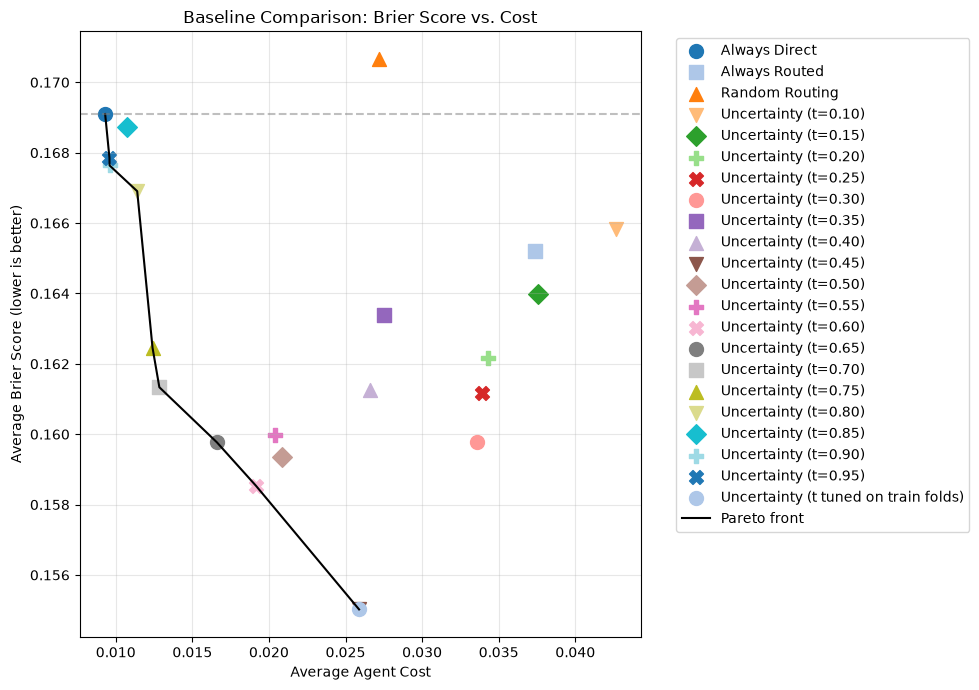

In [75]:
plt.figure(figsize=(10, 7))

markers = ["o", "s", "^", "v", "D", "P", "X"]

for i, (_, row) in enumerate(summary.iterrows()):
    plt.scatter(
        row["Average Cost"],
        row["Average Brier"],
        s=100,
        color=plt.cm.tab20(i % 20),
        marker=markers[i % len(markers)],
        label=row["Model"]
    )

# Pareto front (lower cost AND lower Brier are better, so the best points are bottom-left).
# Go through the policies from cheapest to most expensive and keep a point only if its
# Brier is strictly lower than every cheaper (or equally cheap) point seen so far.
by_cost = summary.sort_values(["Average Cost", "Average Brier"])
front_rows, best_brier = [], np.inf
for _, row in by_cost.iterrows():
    if row["Average Brier"] < best_brier:
        front_rows.append(row)
        best_brier = row["Average Brier"]
front = pd.DataFrame(front_rows)

plt.plot(
    front["Average Cost"],
    front["Average Brier"],
    color="black",
    linewidth=1.5,
    label="Pareto front"
)

plt.xlabel("Average Agent Cost")
plt.ylabel("Average Brier Score (lower is better)")
plt.title("Baseline Comparison: Brier Score vs. Cost")

# Reference line: Brier of always-direct
plt.axhline(summary.loc[summary.Model == "Always Direct", "Average Brier"].iloc[0],
            linestyle="--", color="gray", alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Ridge regression router

Ridge predicts continuous `brier_improvement`. For each grouped cross-validation fold, the model is trained only on the training questions, a routing threshold is selected on that fold's training rows, and the resulting policy is evaluated on held-out questions. 

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Build development features with categories learned from the original training split
dev = pd.concat([train, val], ignore_index=True)
X_dev = make_features(dev, FEATURE_SETS["all"])
y_dev = dev[TARGET].to_numpy()

# Create 101 possible decision threasholds
ridge_thresholds = np.linspace(-1.0, 1.0, 101)
ridge_fold_results = []
ridge_fold_thresholds = []
oof_predictions = np.full(len(dev), np.nan)

for train_idx, heldout_idx in folds:
    ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    )
    ridge.fit(X_dev.iloc[train_idx], y_dev[train_idx])

    train_predictions = ridge.predict(X_dev.iloc[train_idx])
    heldout_predictions = ridge.predict(X_dev.iloc[heldout_idx])
    oof_predictions[heldout_idx] = heldout_predictions

    # Select the threshold using only the training portion of this fold
    best_threshold = min(
        ridge_thresholds,
        key=lambda threshold: evaluate_router(
            lambda data, predictions=(train_predictions > threshold).astype(int): predictions,
            dev.iloc[train_idx],
            lambdas
        )["mean_brier"]
    )
    ridge_fold_thresholds.append(best_threshold)

    heldout_decisions = (heldout_predictions > best_threshold).astype(int)
    ridge_fold_results.append(
        evaluate_router(
            lambda data, predictions=heldout_decisions: predictions,
            dev.iloc[heldout_idx],
            lambdas
        )
    )

ridge_cv_result = average_folds(ridge_fold_results)
ridge_cv_summary = pd.DataFrame([{
    "Model": "Ridge (grouped CV)",
    "Forecast Accuracy": ridge_cv_result["forecast_accuracy"],
    "Oracle Agreement (avg over lambda)": ridge_cv_result["mean_accuracy"],
    "Average Brier Improvement": ridge_cv_result["mean_brier_improvement"],
    "Average Brier": ridge_cv_result["mean_brier"],
    "Brier Std (folds)": ridge_cv_result["brier_std"],
    "Average Cost": ridge_cv_result["mean_cost"],
    "Routing Rate": ridge_cv_result["routing_rate"]
}])

print("Ridge thresholds selected per fold:", ridge_fold_thresholds)
display(ridge_cv_summary.round(5))

Ridge thresholds selected per fold: [np.float64(0.020000000000000018), np.float64(-0.020000000000000018), np.float64(0.020000000000000018), np.float64(-0.020000000000000018), np.float64(0.0)]


,Model,Forecast Accuracy,Oracle Agreement (avg over lambda),Average Brier Improvement,Average Brier,Brier Std (folds),Average Cost,Routing Rate
0,Ridge (grouped CV),0.82243,0.64174,0.03601,0.13309,0.02138,0.02839,0.40719


## Random forest router

Same setup as Ridge: the forest predicts continuous `brier_improvement` from the same features, is trained only on each fold's training questions, and the resulting policy is evaluated on the held-out questions.

The forest is also **tuned** (nested grouped cross-validation). Inside each outer fold, the training questions are split again into 4 inner grouped folds. 

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid

# Settings to try
rf_param_grid = list(ParameterGrid({
    "min_samples_leaf": [5, 10, 20, 40],
    "max_features": [0.33, 0.66, 1.0],
}))
rf_thresholds = np.linspace(-1.0, 1.0, 101)
INNER_K = 4


def make_rf(params):
    return RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42, **params)


def best_threshold_for(predictions, rows):
    """Threshold with the lowest mean Brier on `rows` when routing every row whose prediction is above it."""
    scores = [
        evaluate_router(
            lambda data, p=(predictions > threshold).astype(int): p,
            dev.iloc[rows],
            lambdas
        )["mean_brier"]
        for threshold in rf_thresholds
    ]
    best = int(np.argmin(scores))
    return rf_thresholds[best], scores[best]


rf_fold_results = []
rf_fold_thresholds = []
rf_fold_params = []
rf_oof_predictions = np.full(len(dev), np.nan)

for train_idx, heldout_idx in folds:
    inner_folds = list(GroupKFold(n_splits=INNER_K).split(train_idx, groups=dev["question_id"].to_numpy()[train_idx]))

    best = None 
    for params in rf_param_grid:
        inner_predictions = np.zeros(len(train_idx))
        for inner_train, inner_heldout in inner_folds:
            model = make_rf(params).fit(X_dev.iloc[train_idx[inner_train]], y_dev[train_idx[inner_train]])
            inner_predictions[inner_heldout] = model.predict(X_dev.iloc[train_idx[inner_heldout]])

        # Best threshold for these settings
        threshold, inner_brier = best_threshold_for(inner_predictions, train_idx)
        if best is None or inner_brier < best[0]:
            best = (inner_brier, params, threshold)

    _, best_params, best_threshold = best
    rf_fold_params.append(best_params)
    rf_fold_thresholds.append(best_threshold)

    # Refit the chosen settings on all training questions of this fold, then route the held-out questions
    rf = make_rf(best_params).fit(X_dev.iloc[train_idx], y_dev[train_idx])
    heldout_predictions = rf.predict(X_dev.iloc[heldout_idx])
    rf_oof_predictions[heldout_idx] = heldout_predictions

    heldout_decisions = (heldout_predictions > best_threshold).astype(int)
    rf_fold_results.append(
        evaluate_router(
            lambda data, predictions=heldout_decisions: predictions,
            dev.iloc[heldout_idx],
            lambdas
        )
    )

rf_cv_result = average_folds(rf_fold_results)
rf_cv_summary = pd.DataFrame([{
    "Model": "Random Forest (tuned, grouped CV)",
    "Forecast Accuracy": rf_cv_result["forecast_accuracy"],
    "Oracle Agreement (avg over lambda)": rf_cv_result["mean_accuracy"],
    "Average Brier Improvement": rf_cv_result["mean_brier_improvement"],
    "Average Brier": rf_cv_result["mean_brier"],
    "Brier Std (folds)": rf_cv_result["brier_std"],
    "Average Cost": rf_cv_result["mean_cost"],
    "Routing Rate": rf_cv_result["routing_rate"]
}])

print("Settings and threshold chosen in each fold:")
display(pd.DataFrame(rf_fold_params).assign(threshold=np.round(rf_fold_thresholds, 2)).rename_axis("fold"))
display(rf_cv_summary.round(5))

Settings and threshold chosen in each fold:


,max_features,min_samples_leaf,threshold
fold,,,
0,0.33,40,0.00
1,1.00,5,0.00
2,0.66,40,0.04
3,0.66,5,0.00
4,1.00,5,0.02


,Model,Forecast Accuracy,Oracle Agreement (avg over lambda),Average Brier Improvement,Average Brier,Brier Std (folds),Average Cost,Routing Rate
0,"Random Forest (tuned, grouped CV)",0.80887,0.64604,0.03254,0.13656,0.02628,0.02251,0.32569


### Evaluating Ridge and Random forest against the baselines

All numbers below come from the same 5 grouped folds as the baselines, so they can be compared directly. Two checks:
1. **Comparison table**: Ridge and the random forest next to the baselines.
2. **Plot**: Brier vs. cost for every policy.

In [ ]:
# --- Ridge and Random forest vs. baselines: one comparison table on the same folds ---

# Only baselines whose settings were chosen without looking at the held-out folds. The fixed-t
# uncertainty rows are left out
comparison_results = {
    "Always Direct": all_results["Always Direct"],
    "Always Routed": all_results["Always Routed"],
    "Random Routing": all_results["Random Routing"],
    "Uncertainty (t tuned on train folds)": all_results["Uncertainty (t tuned on train folds)"],
    "Ridge (grouped CV)": ridge_cv_result,
    "Random Forest (tuned, grouped CV)": rf_cv_result,
}

comparison = pd.DataFrame([
    {
        "Model": name,
        "Average Brier": r["mean_brier"],
        "Brier Std (folds)": r["brier_std"],
        "Average Cost": r["mean_cost"],
        "Routing Rate": r["routing_rate"],
        "Forecast Accuracy": r["forecast_accuracy"],
        "Oracle Agreement (avg over lambda)": r["mean_accuracy"],
    }
    for name, r in comparison_results.items()
])

print(f"RIDGE AND RANDOM FOREST vs. BASELINES ({K}-fold grouped CV, held-out folds)")
display(comparison.round(4))

RIDGE AND RANDOM FOREST vs. BASELINES (5-fold grouped CV, held-out folds)


,Model,Average Brier,Brier Std (folds),Average Cost,Routing Rate,Forecast Accuracy,Oracle Agreement (avg over lambda)
0,Always Direct,0.1691,0.0247,0.0093,0.0000,0.7784,0.5965
1,Always Routed,0.1652,0.0286,0.0374,1.0000,0.7817,0.4035
2,Random Routing,0.1707,0.0291,0.0272,0.4695,0.7908,0.5034
3,Uncertainty (t tuned on train folds),0.1550,0.0293,0.0259,0.5056,0.8089,0.6762
4,Ridge (grouped CV),0.1331,0.0214,0.0284,0.4072,0.8224,0.6417
5,"Random Forest (tuned, grouped CV)",0.1366,0.0263,0.0225,0.3257,0.8089,0.6460


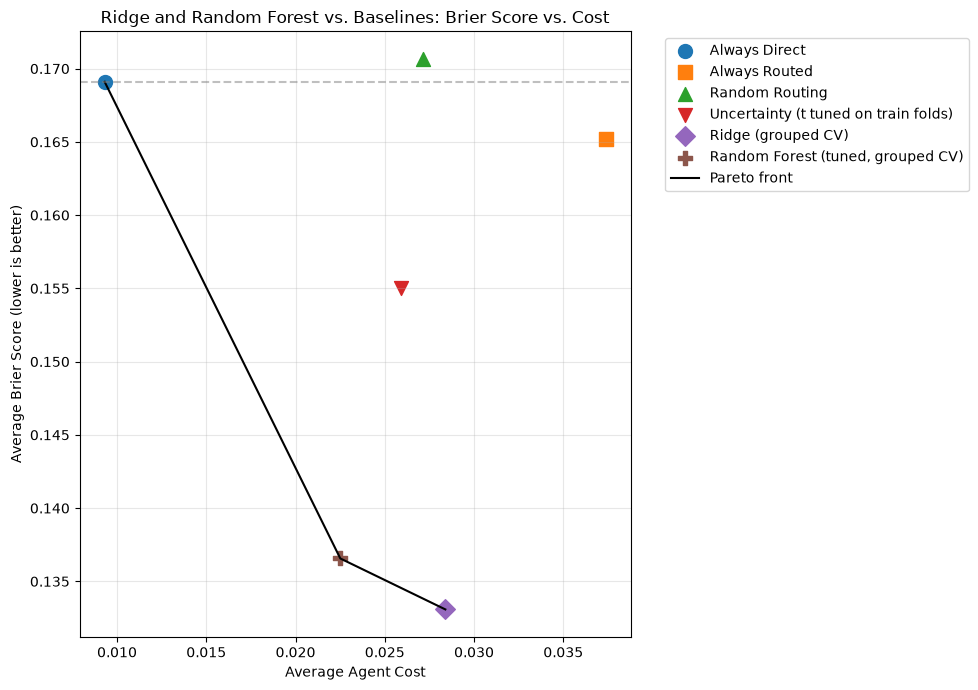

In [ ]:
plt.figure(figsize=(10, 7))

markers = ["o", "s", "^", "v", "D", "P", "X"]

for i, (_, row) in enumerate(comparison.iterrows()):
    plt.scatter(
        row["Average Cost"],
        row["Average Brier"],
        s=100,
        color=plt.cm.tab10(i % 10),  
        marker=markers[i % len(markers)],
        label=row["Model"]
    )

by_cost = comparison.sort_values(["Average Cost", "Average Brier"])
front_rows, best_brier = [], np.inf
for _, row in by_cost.iterrows():
    if row["Average Brier"] < best_brier:
        front_rows.append(row)
        best_brier = row["Average Brier"]
front = pd.DataFrame(front_rows)

plt.plot(
    front["Average Cost"],
    front["Average Brier"],
    color="black",
    linewidth=1.5,
    label="Pareto front"
)

plt.xlabel("Average Agent Cost")
plt.ylabel("Average Brier Score (lower is better)")
plt.title("Ridge and Random Forest vs. Baselines: Brier Score vs. Cost")

plt.axhline(comparison.loc[comparison.Model == "Always Direct", "Average Brier"].iloc[0],
            linestyle="--", color="gray", alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()